# 02 · Synthetic households

This notebook creates the **rows** of the matrix: 5,000 simulated households, and for each one

1. its **traits** (privacy attitudes, drawn at random),
2. its **decision on every item** from notebook 01 (computed from the traits; nobody is asked anything),
3. its **answers to 18 onboarding questions** (computed from the same traits, plus noise).

Later notebooks cluster the decisions (→ presets) and learn which answers predict the cluster (→ onboarding tree).

> **This is not survey data.** Each effect's *direction* comes from the IoT privacy studies below; the *numbers* are
> our choices, all in the configuration cell, so they can be argued about and varied.

| Short | Study |
| --- | --- |
| N17 | Emami-Naeini et al. 2017, *Privacy Expectations and Preferences in an IoT World*, SOUPS |
| N20 | Emami-Naeini et al. 2020, *Ask the Experts: What Should Be on an IoT Privacy and Security Label?*, IEEE S&P |
| N21 | Emami-Naeini et al. 2021, *Which Privacy and Security Attributes Most Impact Consumers' Risk Perception and Willingness to Purchase IoT Devices?*, IEEE S&P |

In [1]:
import hashlib, json
from datetime import date
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
items = pd.read_csv(DATA / "items.csv")          # from notebook 01
FIELDS = ["data_type", "purpose", "action", "source", "handling_context"]
DATA_TYPES = ["ppd:identifierData", "ppd:profileData", "ppd:sensorData", "ppd:contentData", "ppd:locationData", "ppd:deviceAndNetworkData", "ppd:usageData"]
PURPOSES = ["ppd:coreFunctionality", "ppd:personalization", "ppd:communicationsAndNotifications", "ppd:security", "ppd:diagnosticsAndMaintenance", "ppd:analyticsAndImprovement", "ppd:legalCompliance", "ppd:advertisingAndMarketing"]
ACTIONS = ["ppd:collection", "ppd:use", "ppd:transfer", "ppd:inference"]
SOURCES = ["ppd:userProvided", "ppd:participantObserved", "ppd:participantGenerated", "ppd:householdProvided", "ppd:vendorProvided", "ppd:thirdPartyProvided", "ppd:derivedFromPriorData"]
HANDLING_CONTEXTS = ["ppd:householdContext", "ppd:vendorContext", "ppd:thirdPartyContext", "ppd:publicAudience"]
short = lambda term: term.split(":", 1)[1]
print(f"{len(items):,} items loaded")

6,272 items loaded


## Configuration: every number the generator uses

Change values here to try other assumptions. The comment on each says where its direction comes from.

In [2]:
CONFIG = {
    "seed": 20261023,
    "n_households": 5000,

    # Six attitudes, each 0..1, drawn with a Beta(a, b) shape (average a/(a+b)).
    "traits": {
        "concern":               (2.0, 2.0),   # general privacy concern (the standard construct of privacy surveys)
        "vendor_trust":          (3.0, 2.0),   # trust in the device maker; N21: the "device function" purpose was often not trusted
        "third_party_aversion":  (5.0, 2.0),   # N21: sold to third parties raised risk most; N20: all 15 consumers worried about sharing
        "inference_aversion":    (3.0, 2.0),   # N17: inference lowered comfort
        "retention_sensitivity": (3.0, 2.0),   # N17: only short retention clearly raised comfort; N21: no cloud retention lowered risk most
        "benefit_orientation":   (2.5, 2.0),   # N17: benefit to the user raised willingness
    },
    # Correlations between attitudes (unlisted pairs: 0).
    "trait_correlation": {
        ("concern", "vendor_trust"): -0.4,
        ("concern", "third_party_aversion"): 0.5,
        ("concern", "inference_aversion"): 0.5,
        ("concern", "retention_sensitivity"): 0.4,
        ("concern", "benefit_orientation"): -0.3,
        ("third_party_aversion", "inference_aversion"): 0.3,
    },
    "children_rate": 0.35,   # N20: children's data is its own item on the label

    # How sensitive each kind of data is, before each household's own variation. N17: video/biometric least comfortable.
    "data_type_sensitivity": {
        "ppd:contentData": 0.85, "ppd:locationData": 0.75, "ppd:identifierData": 0.70, "ppd:profileData": 0.60,
        "ppd:sensorData": 0.45, "ppd:usageData": 0.40, "ppd:deviceAndNetworkData": 0.25,
    },
    "sensitivity_concern_shift": 0.30,   # sensitivity = base + shift * (concern - 0.5) + noise
    "sensitivity_noise_sd": 0.15,
    "children_bonus": {"ppd:contentData": 0.15, "ppd:locationData": 0.15},

    # How much each purpose benefits the household (-1..1). N17: user benefit and specific purposes raised willingness.
    "purpose_benefit": {
        "ppd:coreFunctionality": 1.0, "ppd:security": 0.9, "ppd:communicationsAndNotifications": 0.7,
        "ppd:diagnosticsAndMaintenance": 0.5, "ppd:legalCompliance": 0.5, "ppd:personalization": 0.4,
        "ppd:analyticsAndImprovement": 0.1, "ppd:advertisingAndMarketing": -0.5,
    },

    # Exposure: how far the data goes. Each entry is (base, trait, weight): base + weight * trait.
    "home_base": 0.10, "away_base": 0.30, "home_action_scale": 0.5,
    "recipient": {
        "ppd:householdContext": (0.0, None, 0.0),
        "ppd:vendorContext": (1.0, "vendor_trust", -1.0),               # less trust in the maker, more exposure
        "ppd:thirdPartyContext": (0.5, "third_party_aversion", 0.7),
        "ppd:publicAudience": (1.5, None, 0.0),
    },
    "action": {
        "ppd:collection": (0.0, None, 0.0),
        "ppd:use": (0.0, None, 0.0),
        "ppd:transfer": (0.3, None, 0.0),                               # N21: sharing/selling lowered comfort
        "ppd:inference": (0.2, "inference_aversion", 0.8),              # N17: inference lowered comfort
    },
    # Where the data comes from (+ = less comfortable).
    "source_term": {
        "ppd:userProvided": -0.10, "ppd:householdProvided": 0.00, "ppd:participantGenerated": 0.05,
        "ppd:vendorProvided": -0.05, "ppd:participantObserved": 0.15, "ppd:thirdPartyProvided": 0.20,
        "ppd:derivedFromPriorData": 0.25,
    },
    "intercept": 0.9, "benefit_weight": 1.0, "risk_weight": 1.8, "decision_noise_sd": 0.30,

    # What each condition is worth (it must lift u above 0 to turn a deny into "allow if ...").
    "ephemeral_gain": 0.9, "ephemeral_home_scale": 0.3, "in_home_removes": 0.8, "on_device_removes": 1.0,

    "answer_noise_sd": 0.12,
}
TRAITS = list(CONFIG["traits"])
rng = np.random.default_rng(CONFIG["seed"])   # one random stream, used in a fixed order -> reproducible

## Step 1 · Traits

Each household gets six attitudes between 0 and 1. They are drawn **together** so some move in step (a concerned
household tends to distrust makers and dislike third parties):

1. draw six numbers from a normal distribution with the correlations above;
2. turn each into a percentile (0..1) with the normal CDF; the correlations survive;
3. map each percentile onto that trait's Beta shape, so each trait has a realistic spread.

This is a *Gaussian copula*.

In [3]:
n = CONFIG["n_households"]
corr = np.eye(len(TRAITS))
for (a, b), r in CONFIG["trait_correlation"].items():
    i, j = TRAITS.index(a), TRAITS.index(b)
    corr[i, j] = corr[j, i] = r

z = rng.multivariate_normal(np.zeros(len(TRAITS)), corr, size=n)    # 1. correlated normal draws
u = stats.norm.cdf(z)                                               # 2. percentiles
H = pd.DataFrame({"household_id": np.arange(n)})
for i, name in enumerate(TRAITS):                                   # 3. Beta shapes
    a, b = CONFIG["traits"][name]
    H[name] = stats.beta.ppf(u[:, i], a, b)
H.head()

,household_id,concern,vendor_trust,third_party_aversion,inference_aversion,retention_sensitivity,benefit_orientation
0,0,0.189976,0.247595,0.384963,0.157240,0.669459,0.833754
1,1,0.348459,0.706440,0.610745,0.451967,0.484456,0.336288
2,2,0.361960,0.370511,0.538608,0.317776,0.458511,0.752090
3,3,0.843306,0.283431,0.757089,0.821178,0.915718,0.770497
4,4,0.951602,0.243487,0.833530,0.598464,0.908358,0.079180


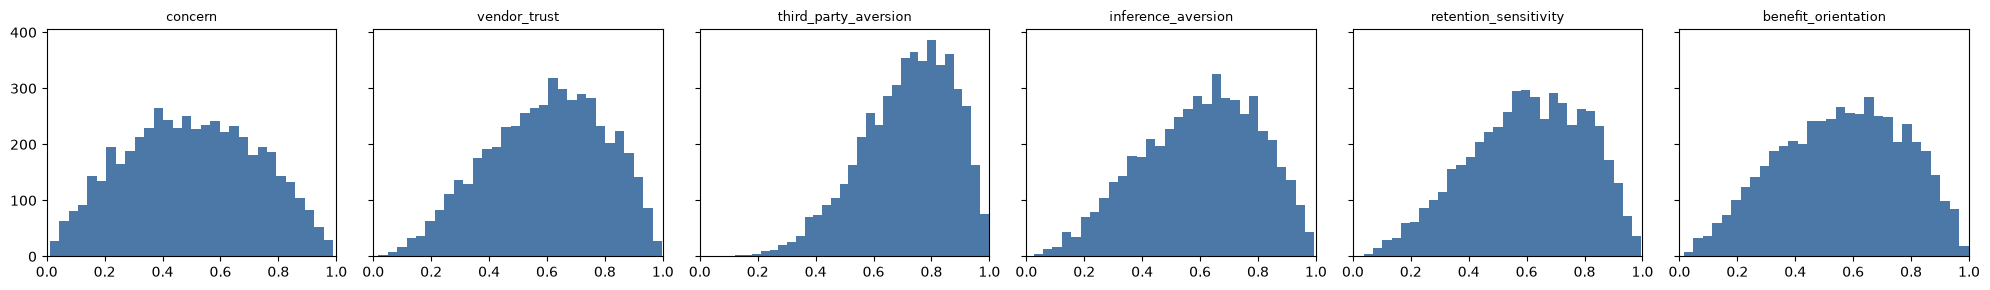

,concern,vendor_trust,third_party_aversion,inference_aversion,retention_sensitivity,benefit_orientation
concern,1.00,-0.39,0.48,0.50,0.39,-0.33
vendor_trust,-0.39,1.00,0.01,0.01,0.02,0.01
third_party_aversion,0.48,0.01,1.00,0.29,-0.00,-0.02
inference_aversion,0.50,0.01,0.29,1.00,0.01,-0.01
retention_sensitivity,0.39,0.02,-0.00,0.01,1.00,-0.03
benefit_orientation,-0.33,0.01,-0.02,-0.01,-0.03,1.00


In [4]:
fig, axes = plt.subplots(1, 6, figsize=(20, 3), sharey=True)
for ax, name in zip(axes, TRAITS):
    ax.hist(H[name], bins=30, color="#4c78a8"); ax.set_title(name, fontsize=9); ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()
H[TRAITS].corr().round(2)   # close to the configured correlations

## Step 2 · Children and sensitivity per data type

- **children**: yes for 35% of households, at random.
- **sensitivity** to each of the 7 data types (0..1): the data type's base sensitivity, shifted up for concerned
  households, plus each household's own noise, plus a bonus for video and location if there are children.

In [5]:
H["children"] = rng.random(n) < CONFIG["children_rate"]

base = np.array([CONFIG["data_type_sensitivity"][d] for d in DATA_TYPES])
shift = CONFIG["sensitivity_concern_shift"] * (H.concern.to_numpy() - 0.5)
sens = base[None, :] + shift[:, None] + rng.normal(0, CONFIG["sensitivity_noise_sd"], size=(n, len(DATA_TYPES)))
bonus = np.array([CONFIG["children_bonus"].get(d, 0.0) for d in DATA_TYPES])
sens = np.clip(sens + H.children.to_numpy()[:, None] * bonus[None, :], 0, 1)
for j, d in enumerate(DATA_TYPES):
    H[f"sens_{short(d)}"] = sens[:, j]
H.filter(like="sens_").describe().loc[["mean", "std"]].round(2)

,sens_identifierData,sens_profileData,sens_sensorData,sens_contentData,sens_locationData,sens_deviceAndNetworkData,sens_usageData
mean,0.70,0.60,0.45,0.87,0.79,0.26,0.40
std,0.16,0.17,0.16,0.14,0.16,0.15,0.16


## Step 3 · The decision on each item

For household *h* and item *i* (one 5-field combination):

```
u = intercept
    + benefit_weight × benefit[purpose] × (0.5 + benefit_orientation)          ← features it values
    − risk_weight × sensitivity[data type] × (0.6 + concern) × exposure        ← risk
    − source_term[source]
    + noise

exposure = home_base + home_action_scale × action_term            if the flow stays home
         = away_base + recipient_term + action_term                otherwise
```

- `u ≥ 0` → **allow**.
- Otherwise, if a condition available for the item lifts `u` to ≥ 0 → **allow if** that condition, checked in the order
  *not kept*, *in-home only*, *on-device only*. (Conditions per item: notebook 01, §3.)
  - not kept is worth `ephemeral_gain × retention_sensitivity × sensitivity` (less when the data stays home);
  - in-home / on-device processing removes most / all of the recipient part of the exposure (use and inference only).
- Otherwise → **deny**.

### One household, one item, by hand

Household 7 and the item *"video sent to the maker for a feature"*:

In [6]:
def term(entry, hh):
    """base + weight * trait, for one household (a row) or all of them (the table)."""
    base, trait, weight = entry
    if trait:
        return base + weight * hh[trait]
    return base if isinstance(hh, pd.Series) else np.full(len(hh), base)

h = 7
example = items[(items.data_type == "ppd:contentData") & (items.purpose == "ppd:coreFunctionality") &
                (items.action == "ppd:transfer") & (items.source == "ppd:participantObserved") &
                (items.handling_context == "ppd:vendorContext")].iloc[0]
hh = H.loc[h]
s = hh[f"sens_{short(example.data_type)}"]
act, rec = term(CONFIG["action"][example.action], hh), term(CONFIG["recipient"][example.handling_context], hh)
home = not example.leaves_home
exposure = CONFIG["home_base"] + CONFIG["home_action_scale"] * act if home else CONFIG["away_base"] + rec + act
benefit_part = CONFIG["benefit_weight"] * CONFIG["purpose_benefit"][example.purpose] * (0.5 + hh.benefit_orientation)
risk_part = CONFIG["risk_weight"] * s * (0.6 + hh.concern) * exposure
source_part = CONFIG["source_term"][example.source]
pd.Series({"intercept": CONFIG["intercept"], "+ benefit": benefit_part, "- risk": -risk_part,
           "- source": -source_part, "= u before noise": CONFIG["intercept"] + benefit_part - risk_part - source_part}).round(3)

intercept           0.900
+ benefit           0.936
- risk             -2.015
- source           -0.150
= u before noise   -0.329
dtype: float64

### All households, all items

The same formula for 5,000 × 6,272 decisions at once (in blocks of 1,000 households). The noise is drawn here.

In [7]:
DENY, ALLOW, IF_EPHEMERAL, IF_IN_HOME, IF_ON_DEVICE = 0, 1, 2, 3, 4
DECISION_CODES = {0: "deny", 1: "allow", 2: "allow_if:retention=ppd:ephemeral",
                  3: "allow_if:processing_boundary=ppd:inHomeOnly", 4: "allow_if:processing_boundary=ppd:onDeviceOnly"}

def per_household(table, terms):
    return np.stack([term(table[t], H) for t in terms], axis=1)

recipient = per_household(CONFIG["recipient"], HANDLING_CONTEXTS)     # [households x 4]
action = per_household(CONFIG["action"], ACTIONS)                      # [households x 4]
benefit = np.array([CONFIG["purpose_benefit"][p] for p in PURPOSES])
source = np.array([CONFIG["source_term"][s] for s in SOURCES])

d_idx = items.data_type.map(DATA_TYPES.index).to_numpy()
p_idx = items.purpose.map(PURPOSES.index).to_numpy()
a_idx = items.action.map(ACTIONS.index).to_numpy()
s_idx = items.source.map(SOURCES.index).to_numpy()
c_idx = items.handling_context.map(HANDLING_CONTEXTS.index).to_numpy()
home = ~items.leaves_home.to_numpy()
boundary_ok = items.action.isin(["ppd:use", "ppd:inference"]).to_numpy()
concern, orient, retention = H.concern.to_numpy(), H.benefit_orientation.to_numpy(), H.retention_sensitivity.to_numpy()

m = len(items)
D = np.zeros((n, m), dtype=np.uint8)
for start in range(0, n, 1000):
    sl = slice(start, min(start + 1000, n))
    s_h, act, rec = sens[sl][:, d_idx], action[sl][:, a_idx], recipient[sl][:, c_idx]
    exposure = np.where(home[None, :], CONFIG["home_base"] + CONFIG["home_action_scale"] * act, CONFIG["away_base"] + rec + act)
    scale = CONFIG["risk_weight"] * s_h * (0.6 + concern[sl, None])
    u = (CONFIG["intercept"]
         + CONFIG["benefit_weight"] * benefit[p_idx][None, :] * (0.5 + orient[sl, None])
         - scale * exposure
         - source[s_idx][None, :]
         + rng.normal(0, CONFIG["decision_noise_sd"], size=(sl.stop - sl.start, m)))
    # What each condition is worth for this household and item.
    gain_ephemeral = CONFIG["ephemeral_gain"] * retention[sl, None] * s_h * np.where(home, CONFIG["ephemeral_home_scale"], 1.0)[None, :]
    away_part = np.where(home[None, :], 0.0, rec)
    gain_in_home = np.where(boundary_ok[None, :], scale * CONFIG["in_home_removes"] * away_part, -np.inf)
    gain_on_device = np.where(boundary_ok[None, :], scale * CONFIG["on_device_removes"] * (away_part + np.where(home, CONFIG["home_base"], 0.0)[None, :]), -np.inf)
    d = np.full(u.shape, DENY, dtype=np.uint8)          # later lines win: allow beats every condition,
    d[(u + gain_on_device) >= 0] = IF_ON_DEVICE         # and "not kept" is tried before in-home, in-home before on-device
    d[(u + gain_in_home) >= 0] = IF_IN_HOME
    d[(u + gain_ephemeral) >= 0] = IF_EPHEMERAL
    d[u >= 0] = ALLOW
    D[sl] = d

print(f"{D.size:,} decisions; household {h} on the example item: {DECISION_CODES[int(D[h, example.item_id])]}")
pd.Series({DECISION_CODES[k]: (D == k).mean() for k in DECISION_CODES}).map("{:.1%}".format).rename("share")

31,360,000 decisions; household 7 on the example item: deny


deny                                             28.0%
allow                                            53.9%
allow_if:retention=ppd:ephemeral                  7.4%
allow_if:processing_boundary=ppd:inHomeOnly       7.7%
allow_if:processing_boundary=ppd:onDeviceOnly     3.0%
Name: share, dtype: str

## Step 4 · Do the effects point the way the studies say?

Mean acceptance (deny 0, allow-if 0.5, allow 1) per term of each field.

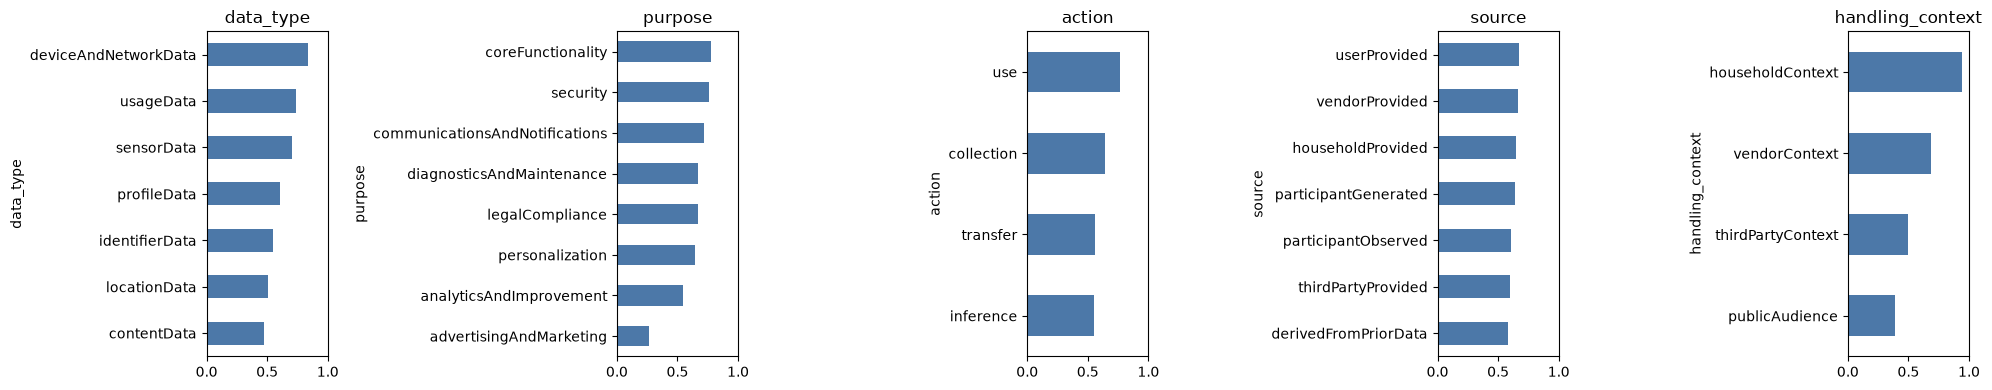

video (content) is the least accepted data type (N17)    True
advertising is the least accepted purpose                True
staying home is the most accepted                        True
third parties below the maker (N21)                      True
inference below use (N17)                                True
more concern, fewer allows                               True
Name: holds, dtype: bool

In [8]:
ORDINAL = np.array([0.0, 1.0, 0.5, 0.5, 0.5], dtype=np.float32)
V = ORDINAL[D]
item_mean = pd.Series(V.mean(axis=0))
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, f in zip(axes, FIELDS):
    item_mean.groupby(items[f].map(short)).mean().sort_values().plot.barh(ax=ax, color="#4c78a8")
    ax.set_xlim(0, 1); ax.set_title(f)
plt.tight_layout(); plt.show()
checks = {
    "video (content) is the least accepted data type (N17)": item_mean.groupby(items.data_type).mean().idxmin() == "ppd:contentData",
    "advertising is the least accepted purpose": item_mean.groupby(items.purpose).mean().idxmin() == "ppd:advertisingAndMarketing",
    "staying home is the most accepted": item_mean.groupby(items.handling_context).mean().idxmax() == "ppd:householdContext",
    "third parties below the maker (N21)": item_mean[items.handling_context == "ppd:thirdPartyContext"].mean() < item_mean[items.handling_context == "ppd:vendorContext"].mean(),
    "inference below use (N17)": item_mean[items.action == "ppd:inference"].mean() < item_mean[items.action == "ppd:use"].mean(),
    "more concern, fewer allows": np.corrcoef(H.concern, (D == ALLOW).mean(axis=1))[0, 1] < -0.5,
}
assert all(checks.values()), checks
pd.Series(checks, name="holds")

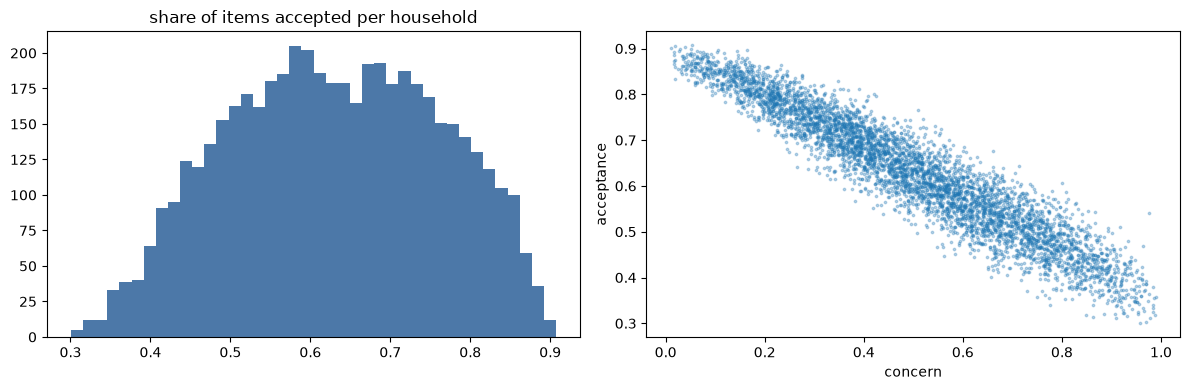

acceptance quantiles (0, 10, 50, 90, 100%): [0.3  0.45 0.63 0.81 0.91]


In [9]:
perm = V.mean(axis=1)
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
a.hist(perm, bins=40, color="#4c78a8"); a.set_title("share of items accepted per household")
b.scatter(H.concern, perm, s=3, alpha=0.3); b.set_xlabel("concern"); b.set_ylabel("acceptance")
plt.tight_layout(); plt.show()
print("acceptance quantiles (0, 10, 50, 90, 100%):", np.quantile(perm, [0, .1, .5, .9, 1]).round(2))

## Step 5 · Answers to the onboarding questions

The question bank comes from the app's questionnaire (`ppd-preference-app/public/mock/questionnaire.json`):
Q1 children; Q2's six data rows and Q3's six purpose rows as separate questions (so a decision tree can pick single
rows); Q4 sharing, Q5 inference, Q6 retention. Q7 (notifications) is left out because it sets no rules. Two
questions are ours: `concern` and `trust_maker` (1–5).

The app's Q3 does not cover `ppd:security` or `ppd:legalCompliance`; here security is grouped with "making a feature
work" and legal duties with "fixing problems", so every purpose is reached.

Each answer is computed from the household's traits **plus noise** (people don't answer exactly in line with their
preferences). Answers are coded never < ask < fine.

In [10]:
THREE = ["never", "ask", "fine"]
DATA_GROUPS = {   # app Q2 rows
    "content": (["ppd:contentData"], "Video, photos and sound"),
    "location": (["ppd:locationData"], "Where you are"),
    "identity": (["ppd:identifierData", "ppd:profileData"], "Who you are (accounts, names, profile)"),
    "sensor": (["ppd:sensorData"], "Sensor readings (temperature, motion, …)"),
    "usage": (["ppd:usageData"], "How you use the device"),
    "network": (["ppd:deviceAndNetworkData"], "Device and network details"),
}
PURPOSE_GROUPS = {   # app Q3 rows (+ security, legal compliance)
    "core": (["ppd:coreFunctionality", "ppd:security"], "Making a feature work, keeping it secure"),
    "comms": (["ppd:communicationsAndNotifications"], "Sending you alerts and messages"),
    "diag": (["ppd:diagnosticsAndMaintenance", "ppd:legalCompliance"], "Fixing problems, legal duties"),
    "analytics": (["ppd:analyticsAndImprovement"], "Improving their products"),
    "personal": (["ppd:personalization"], "Personalizing what you see"),
    "ads": (["ppd:advertisingAndMarketing"], "Advertising and marketing"),
}
QUESTIONS = [
    {"id": "children", "text": "Do children live in your home, or visit often?", "options": ["yes", "no"], "from": "children (app Q1)"},
    {"id": "concern", "text": "How much do you worry about what smart devices do with your data?", "options": list("12345"), "from": "concern (ours)"},
    {"id": "trust_maker", "text": "How much do you trust device makers with your data?", "options": list("12345"), "from": "vendor_trust (ours)"},
    *[{"id": f"data_{k}", "text": f"{label}: may it leave your home?", "options": THREE, "from": f"sensitivity to {', '.join(map(short, t))} + concern (app Q2)"} for k, (t, label) in DATA_GROUPS.items()],
    *[{"id": f"purpose_{k}", "text": f"May companies use your data for: {label.lower()}?", "options": THREE, "from": "benefit_orientation + concern (app Q3)"} for k, (t, label) in PURPOSE_GROUPS.items()],
    {"id": "sharing", "text": "May a device's maker pass your data to other companies?", "options": ["never", "ask", "features"], "from": "third_party_aversion (app Q4)"},
    {"id": "inference", "text": "May companies work out extra things about you from your data?", "options": ["never", "ask", "ok"], "from": "inference_aversion (app Q5)"},
    {"id": "retention", "text": "How long may companies keep your data?", "options": ["briefly", "ask", "any"], "from": "retention_sensitivity (app Q6)"},
]
pd.DataFrame(QUESTIONS).set_index("id")[["text", "from"]]

,text,from
id,,
children,"Do children live in your home, or visit often?",children (app Q1)
concern,How much do you worry about what smart devices...,concern (ours)
trust_maker,How much do you trust device makers with your ...,vendor_trust (ours)
data_content,"Video, photos and sound: may it leave your home?",sensitivity to contentData + concern (app Q2)
data_location,Where you are: may it leave your home?,sensitivity to locationData + concern (app Q2)
data_identity,"Who you are (accounts, names, profile): may it...","sensitivity to identifierData, profileData + c..."
data_sensor,"Sensor readings (temperature, motion, …): may ...",sensitivity to sensorData + concern (app Q2)
data_usage,How you use the device: may it leave your home?,sensitivity to usageData + concern (app Q2)
data_network,Device and network details: may it leave your ...,sensitivity to deviceAndNetworkData + concern ...


In [11]:
answer_rng = np.random.default_rng(CONFIG["seed"] + 1)   # a separate stream, so answers don't shift the decisions
noise = lambda: answer_rng.normal(0, CONFIG["answer_noise_sd"], n)

def three(score, low, high, labels=THREE):      # 0..1, higher = more permissive
    return np.where(score < low, labels[0], np.where(score > high, labels[2], labels[1]))

def likert(score):                              # 0..1 -> "1".."5"
    return np.clip(np.rint(1 + 4 * score), 1, 5).astype(int).astype(str)

A = pd.DataFrame({"household_id": H.household_id})
A["children"] = np.where(H.children, "yes", "no")
A["concern"] = likert(np.clip(concern + noise(), 0, 1))
A["trust_maker"] = likert(np.clip(H.vendor_trust.to_numpy() + noise(), 0, 1))
for key, (terms, _) in DATA_GROUPS.items():
    s = H[[f"sens_{short(t)}" for t in terms]].to_numpy().mean(axis=1)
    A[f"data_{key}"] = three(1 - s * (0.6 + concern) / 1.6 + noise(), 0.35, 0.65)
for key, (terms, _) in PURPOSE_GROUPS.items():
    b = np.mean([CONFIG["purpose_benefit"][t] for t in terms])
    A[f"purpose_{key}"] = three(0.5 + 0.35 * b * (0.5 + orient) - 0.4 * (concern - 0.5) + noise(), 0.4, 0.7)
A["sharing"] = three(1 - H.third_party_aversion.to_numpy() + noise(), 0.3, 0.6, ["never", "ask", "features"])
A["inference"] = three(1 - H.inference_aversion.to_numpy() + noise(), 0.3, 0.6, ["never", "ask", "ok"])
A["retention"] = three(1 - H.retention_sensitivity.to_numpy() + noise(), 0.3, 0.6, ["briefly", "ask", "any"])

for q in QUESTIONS:
    assert set(A[q["id"]]) <= set(q["options"]), q["id"]
pd.DataFrame({q["id"]: A[q["id"]].value_counts(normalize=True).round(2).to_dict() for q in QUESTIONS}).T.fillna("")

/tmp/ipykernel_425387/2588522786.py:26: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  pd.DataFrame({q["id"]: A[q["id"]].value_counts(normalize=True).round(2).to_dict() for q in QUESTIONS}).T.fillna("")


,no,yes,3,2,4,5,1,ask,never,fine,features,ok,briefly,any
children,0.65,0.35,,,,,,,,,,,,
concern,,,0.34,0.26,0.26,0.07,0.07,,,,,,,
trust_maker,,,0.34,0.16,0.36,0.11,0.02,,,,,,,
data_content,,,,,,,,0.45,0.42,0.13,,,,
data_location,,,,,,,,0.51,0.32,0.18,,,,
data_identity,,,,,,,,0.53,0.17,0.31,,,,
data_sensor,,,,,,,,0.37,0.05,0.58,,,,
data_usage,,,,,,,,0.33,0.03,0.64,,,,
data_network,,,,,,,,0.16,0.01,0.83,,,,
purpose_core,,,,,,,,0.2,0.0,0.8,,,,


### How each answer relates to each trait

Rank correlation between every trait and every answer (answers coded so higher = more permissive, so aversions and
sensitivities show as negative). Each question should track its own trait; note how much **concern** bleeds into
the data and purpose questions, and that the purpose questions share one trait.

In [12]:
codes = {"never": 0, "ask": 1, "fine": 2, "features": 2, "ok": 2, "briefly": 0, "any": 2, "no": 0, "yes": 1}
num = A.drop(columns="household_id").apply(lambda c: pd.to_numeric(c.map(lambda v: codes.get(v, v))))
cols = TRAITS + ["children"] + [c for c in H.columns if c.startswith("sens_")]
Hn = H.assign(children=H.children.astype(int))
pd.DataFrame({q: [num[q].corr(Hn[c], method="spearman") for c in cols] for q in num.columns}, index=cols).T.round(2)

,concern,vendor_trust,third_party_aversion,inference_aversion,retention_sensitivity,benefit_orientation,children,sens_identifierData,sens_profileData,sens_sensorData,sens_contentData,sens_locationData,sens_deviceAndNetworkData,sens_usageData
children,0.00,-0.02,-0.00,0.01,-0.01,0.01,1.00,0.01,-0.01,-0.02,0.38,0.38,0.00,-0.01
concern,0.85,-0.33,0.40,0.42,0.33,-0.27,-0.01,0.34,0.35,0.34,0.29,0.30,0.35,0.36
trust_maker,-0.32,0.82,-0.00,0.00,0.03,0.01,-0.02,-0.14,-0.15,-0.10,-0.13,-0.12,-0.12,-0.12
data_content,-0.66,0.25,-0.30,-0.33,-0.26,0.21,-0.15,-0.27,-0.26,-0.26,-0.58,-0.30,-0.27,-0.26
data_location,-0.63,0.24,-0.31,-0.33,-0.24,0.18,-0.16,-0.29,-0.25,-0.24,-0.27,-0.60,-0.26,-0.28
data_identity,-0.64,0.24,-0.31,-0.32,-0.24,0.20,0.00,-0.48,-0.48,-0.25,-0.22,-0.23,-0.26,-0.28
data_sensor,-0.48,0.16,-0.22,-0.24,-0.19,0.17,0.01,-0.21,-0.18,-0.60,-0.17,-0.16,-0.19,-0.21
data_usage,-0.45,0.14,-0.22,-0.24,-0.18,0.15,-0.01,-0.19,-0.19,-0.17,-0.16,-0.17,-0.17,-0.59
data_network,-0.35,0.12,-0.17,-0.19,-0.14,0.09,-0.00,-0.14,-0.15,-0.12,-0.11,-0.15,-0.49,-0.14
purpose_core,-0.45,0.14,-0.17,-0.17,-0.13,0.41,-0.02,-0.19,-0.17,-0.19,-0.15,-0.17,-0.18,-0.20


## Step 6 · Save

- `data/households.csv`, `data/answers.csv`, `data/decisions.npy` (uint8, codes in `decision_codes.json`) — gitignored;
- `data/sample/`: the first 200 households, and their decisions on the 52 real-device items in readable form — committed;
- `data/DATACARD.md`, including a SHA-256 of the decisions: same config + seed ⇒ same hash.

In [13]:
DATA.mkdir(exist_ok=True)
H.to_csv(DATA / "households.csv", index=False, float_format="%.4f")
A.to_csv(DATA / "answers.csv", index=False)
np.save(DATA / "decisions.npy", D)
(DATA / "decision_codes.json").write_text(json.dumps({str(k): v for k, v in DECISION_CODES.items()}, indent=2) + "\n")

sample = DATA / "sample"; sample.mkdir(exist_ok=True)
ids = list(range(200))
H.iloc[ids].to_csv(sample / "households.csv", index=False, float_format="%.4f")
A.iloc[ids].to_csv(sample / "answers.csv", index=False)
np.save(sample / "decisions.npy", D[ids])
real = items[items.in_corpus]
long = pd.DataFrame([(hid, i, DECISION_CODES[int(D[hid, i])]) for hid in ids for i in real.item_id],
                    columns=["household_id", "item_id", "decision"]).merge(items[["item_id", *FIELDS]], on="item_id")
long.to_csv(sample / "decisions_corpus_items.csv", index=False)

sha = hashlib.sha256(D.tobytes()).hexdigest()
shares = "\n".join(f"| `{v}` | {(D == k).mean():.1%} |" for k, v in DECISION_CODES.items())
(DATA / "DATACARD.md").write_text(f'''# Data card: synthetic PPD household preferences

Generated {date.today().isoformat()} by `notebooks/02_generate_households.ipynb` (seed {CONFIG['seed']}); items from
`notebooks/01_items.ipynb`. Same notebooks and seed reproduce the same data (SHA-256 below).

## What it is

{n:,} synthetic households and their decision on each of the {m:,} core PPD dataflows (data type x purpose x action x
source x handling context, draft-dsmullen-ppd-taxonomy-05 section 6), plus their answers to {len(QUESTIONS)} candidate
onboarding questions.

**This is not survey data.** Decisions follow from latent traits and weights chosen in notebook 02; directions come
from Emami-Naeini et al. 2017, 2020, 2021, magnitudes are ours. Use it to build and test the pipeline, not to claim how
real households behave. Why one decision per 5-field combination and why qualifiers are conditions inside a decision:
notebook 01 and README.md ("How this follows the PPD drafts").

## Files

| File | Contents |
| --- | --- |
| `items.csv` | the {m:,} items with flags (notebook 01) |
| `households.csv` | household_id, 6 traits (0..1), children, sensitivity per data type |
| `answers.csv` | household_id, one column per question |
| `decisions.npy` | uint8 [households x items]; codes in `decision_codes.json` |
| `sample/` | the first 200 households; their decisions on the {len(real)} real-device items, readable (committed) |

{int(items.in_corpus.sum())} of {m:,} items are declared by the researched devices; {int(items.plausible.sum()):,} pass the plausibility
check. Nothing is filtered out.

## Decision shares

| Decision | Share |
| --- | --- |
{shares}

Decisions SHA-256: `{sha}`

## Known limits

- Weights are our reading of the literature; a planned sensitivity notebook varies them.
- One trait (concern) dominates; purposes share one household-level trait; noise is drawn per decision.
- Answers come from the same traits as decisions (answer noise {CONFIG['answer_noise_sd']}); real people are less consistent.
- "Ask" is never a decision (PPD effects are allow and deny); it appears only as an answer.
- One condition per cell (a rule may carry several qualifiers); jurisdiction is not modelled.
''')
print("decisions SHA-256:", sha)

decisions SHA-256: 6560c4fb258e6581381db5f3961957c6ea90eb360be114a0f300986193e5e0a0
